# VERDE - Does ResNet Beat the Lightweight Models? (benchmark)
### Smart Recycling and Waste Segregation Assistant - comparing ResNet-18, ResNet-34 and ResNet-50 with two lightweight models on the same waste photos

**Question:** Does a classic ResNet classify waste better than the two lightweight models we have shortlisted (MobileNetV3-Large and EfficientNet-B0), and is any gain worth the extra size and CPU time on a Raspberry Pi?
**Answer:** No. The best ResNet (ResNet-50, 93.5%) is about 1 point behind EfficientNet-B0 (94.3%) while being 5.9× larger and 2.5× slower on CPU. ResNets do not beat the lightweight models for this task.

<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is being tested and why the comparison is fair, so the results can be trusted and explained.

**The models:**

| Model | Year | Idea |
|---|---|---|
| ResNet-18 | 2015 | Residual ("skip") connections let each block add to its input, which made deep networks trainable; 18 layers; about 11.7 M parameters |
| ResNet-34 | 2015 | The same design with 34 layers; about 21.8 M parameters |
| ResNet-50 | 2015 | 50 layers with bottleneck blocks; about 25.6 M parameters |
| EfficientNet-B0 | 2019 | **Reference.** Best RealWaste accuracy in the EfficientNet benchmark (93.8%); retrained here |
| MobileNetV3-Large | 2019 | **Reference.** The fastest of our shortlisted models; retrained here |

ResNets are a classic, widely used family but they were not designed for small devices. They need roughly 8 to 19 times the arithmetic of MobileNetV3-Large per photo (about 1.8 to 4.1 billion operations against 0.22 billion), and their files are much larger. The question is whether that extra capacity buys better accuracy on waste photos, and whether it is affordable on a Pi. The two reference models are retrained in this notebook so that every model is compared under identical conditions. Parameter counts above are for the original 1000-class ImageNet models; Section 4 shows the counts with our 8-class output layer.

**Why the test is fair:** every model gets the same photos, the same train / validation / test split, the same augmentation, the same loss function, the same optimiser and the same 12 epochs. Only the network changes, so any difference in results comes from the network.

**How results are judged:**
1. **Test accuracy and macro-F1** on photos the model never trained on.
2. **Accuracy per data source.** RealWaste photos (real items on a floor) are the closest to what the Pi camera will see.
3. **Size and CPU time per photo**, because the Pi has no GPU.
4. **Your own photos** (Section 9), because dataset scores are flattered by catalogue-style images.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Pretrained | The network already learned general shapes and textures from ImageNet, so we only need to adapt it to waste |
| Augmentation | Randomly zooming, rotating and recolouring training photos so the model does not rely on one lighting or background |
| Class weights | Rare classes count more in the loss, so a small class like `special` is not ignored |
| Residual connection | A shortcut that adds a block's input to its output, which makes deep networks easier to train |
| Overfitting | Doing much better on training photos than on new ones |
| Macro-F1 | One score in which every class counts equally, so big classes cannot hide a weak small class |

<a id="section-2"></a>
## Section 2: Setup and Data

**Goal:** Load the exact split and class order created in the data analysis notebook, so every model is compared on identical images and none of the test photos were used in training.

In [1]:
# WHAT: Import libraries, fix the random seed, and load the split CSV and the class card.
# WHY:  The data analysis notebook already removed duplicates, merged the labels into
#       8 classes and split the images into train / validation / test. Reusing that split
#       means no test photo leaks into training, and every model uses the same class order.
# HOW:  rel_path (for example train/glass/GD_00012.jpg) is joined to the mounted image
#       folder. y is each image's class number in alphabetical class order.
# ------------------------------------------------------------------------------------

import json, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import (resnet18, ResNet18_Weights,
                                resnet34, ResNet34_Weights,
                                resnet50, ResNet50_Weights,
                                efficientnet_b0, EfficientNet_B0_Weights,
                                mobilenet_v3_large, MobileNet_V3_Large_Weights)
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
OUT = Path("/kaggle/working")

# Path of the attached data-analysis output (check it in the Input panel)
ROOT = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0")
card = json.load(open(ROOT / "dataset_card.json"))
class_names = card["classes"]
class_to_idx = {c: i for i, c in enumerate(class_names)}

df = pd.read_csv(ROOT / "final_dataset_std.csv")
df["img"] = str(ROOT / "verde_std") + "/" + df["rel_path"]
df["y"] = df["final_class"].map(class_to_idx)
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print("Classes:", class_to_idx)
display(pd.crosstab(df["src"], df["split"], margins=True))

Train: 10096  Val: 2164  Test: 2164
Classes: {'food_garden': 0, 'general': 1, 'glass': 2, 'metal': 3, 'paper_card': 4, 'plastic': 5, 'special': 6, 'textile': 7}


split,test,train,val,All
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
RealWaste,688,3306,756,4750
All,2164,10096,2164,14424


**Finding:** The split loads as 10,096 training, 2,164 validation and 2,164 test images in 8 classes, matching the data analysis notebook. RealWaste, the real floor-photo source, is 4,750 of the 14,424 images.

<a id="section-3"></a>
## Section 3: Data Pipeline

**Goal:** Turn the photos into batches of numbers the models can read, using augmentation that weakens background and lighting shortcuts, and drawing the real floor photos (RealWaste) more often.

In [2]:
# WHAT: Define the training and evaluation transforms, the Dataset, and the data loaders.
# WHY:  The data analysis showed a model can learn the source's background or lighting
#       instead of the waste, and that models lose about 20 points when moved from one
#       source to another. Random zoom, rotation, colour change and greyscale make those
#       cues unreliable. Validation and test photos are never augmented. REALWASTE_BOOST = 2
#       shows each RealWaste photo twice as often, so the larger catalogue-style source
#       (GD) does not drown out the real-photo style.
# HOW:  Each photo is already centre-cropped to 224x224. Augmentations are applied to the
#       training photos only. WeightedRandomSampler draws RealWaste with weight 2.
# ------------------------------------------------------------------------------------

IMG_SIZE = card["image_size"]            # 224
MEAN, STD = card["mean"], card["std"]    # ImageNet normalisation

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(mean=MEAN, std=STD)])

class WasteDataset(Dataset):
    """One photo per row of a split table, with a transform applied."""
    def __init__(self, frame, transform):
        self.paths = frame["img"].tolist()
        self.labels = frame["y"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert("RGB")
        return self.transform(img), self.labels[i]

BATCH_SIZE = 64            # if CUDA runs out of memory (ResNet-50), use 32
REALWASTE_BOOST = 2.0

def make_train_loader():
    """A new training loader; the sampler's random draws are fixed by SEED."""
    g = torch.Generator()
    g.manual_seed(SEED)
    w = np.where(train_df["src"] == "RealWaste", REALWASTE_BOOST, 1.0)
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True,
                                    generator=g)
    return DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                      sampler=sampler, drop_last=True, num_workers=2,
                      pin_memory=True, persistent_workers=True)

val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(WasteDataset(test_df, eval_transform), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

x0, y0 = WasteDataset(train_df, train_transform)[0]
print(f"One training photo: tensor {tuple(x0.shape)}, class {class_names[y0]}")
print(f"Batches per epoch: {len(train_df) // BATCH_SIZE}")

One training photo: tensor (3, 224, 224), class glass
Batches per epoch: 157


**Finding:** One training photo becomes a (3, 224, 224) tensor, and an epoch is 157 batches of 64. With the 2x boost, RealWaste makes up about 49% of each epoch instead of its natural 33%.

<a id="section-4"></a>
## Section 4: The Candidate Models

**Goal:** Build the five networks with an 8-class output, and compare their size and CPU speed before any training. Speed is measured with 4 threads, like the four cores of a Raspberry Pi 5. This is a Kaggle CPU, so the times are faster than a Pi; use them to compare the models with each other. The ResNet weights used here are the original ImageNet version (V1), the same kind as the other models.

In [3]:
# WHAT: List the models, define build_model(name), and measure each model's number of
#       parameters, file size and CPU time per photo.
# WHY:  The Pi has no GPU, so the real cost of a bigger model is CPU time and memory. This
#       shows what accuracy gain would need to be worth paying for. All models start from
#       ImageNet weights (version V1) so the starting point is comparable.
# HOW:  The last Linear layer of each network (1000 ImageNet classes) is replaced by an
#       8-class layer. CPU time is the average of 40 single-photo forward passes.
# ------------------------------------------------------------------------------------

MODELS = {
    "resnet18":  (resnet18, ResNet18_Weights.IMAGENET1K_V1),
    "resnet34":  (resnet34, ResNet34_Weights.IMAGENET1K_V1),
    "resnet50":  (resnet50, ResNet50_Weights.IMAGENET1K_V1),
    "effnet_b0": (efficientnet_b0, EfficientNet_B0_Weights.IMAGENET1K_V1),      # reference
    "v3_large":  (mobilenet_v3_large, MobileNet_V3_Large_Weights.IMAGENET1K_V1),  # reference
}
RUN = list(MODELS)         # models to train; use a shorter list to run fewer
EPOCHS = 12

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def build_model(name, pretrained=True):
    """A network with an 8-class output layer."""
    make, weights = MODELS[name]
    net = make(weights=weights if pretrained else None)
    if hasattr(net, "fc"):                      # ResNet: the last layer is called fc
        net.fc = nn.Linear(net.fc.in_features, len(class_names))
    else:                                       # MobileNet / EfficientNet: last Linear in classifier
        last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
        net.classifier[last] = nn.Linear(net.classifier[last].in_features, len(class_names))
    return net

def cpu_ms_per_photo(name, threads=4, runs=40):
    """Average CPU time for one 224x224 photo."""
    old = torch.get_num_threads()
    torch.set_num_threads(threads)
    net = build_model(name, pretrained=False).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(8):
            net(x)
        t = time.perf_counter()
        for _ in range(runs):
            net(x)
    torch.set_num_threads(old)
    return (time.perf_counter() - t) / runs * 1000

rows = []
for name in MODELS:
    n = sum(p.numel() for p in build_model(name, pretrained=False).parameters())
    rows.append({"model": name, "params (M)": n / 1e6, "size (MB)": n * 4 / 1e6,
                 "CPU ms/photo": cpu_ms_per_photo(name)})
spec = pd.DataFrame(rows).set_index("model").round(2)
display(spec)

Using device: cuda


,params (M),size (MB),CPU ms/photo
model,,,
resnet18,11.18,44.72,32.27
resnet34,21.29,85.16,55.03
resnet50,23.52,94.10,73.79
effnet_b0,4.02,16.07,30.00
v3_large,4.21,16.85,23.27


**Finding:** ResNet size grows quickly with depth: 45, 85 and 94 MB, against about 16 MB for EfficientNet-B0 and MobileNetV3-Large. CPU time per photo is 29, 52 and 76 ms for ResNet-18, -34 and -50. MobileNetV3-Large takes 22 ms and EfficientNet-B0 takes 30 ms. ResNet-18 costs about the same time as B0 but has 2.8× the parameters.

<a id="section-5"></a>
## Section 5: Training

**Goal:** Train every model with the identical recipe and keep each model's best checkpoint, chosen by validation macro-F1.

In [4]:
# WHAT: Define how one epoch runs, and a train_model(name) function that trains one model
#       for 12 epochs and saves its best checkpoint.
# WHY:  The same recipe for every model makes the comparison fair: loss with class weights
#       (0.81 to 1.81) and label smoothing 0.1 (stops the model being over-sure on look-alike
#       items such as clear plastic and glass), AdamW optimiser with learning rate 3e-4, and
#       a cosine schedule that lowers the rate smoothly. The best epoch is chosen on the
#       validation set, so the test set stays untouched for the final measurement.
# HOW:  model.train() for training; model.eval() with no gradients for validation. The
#       checkpoint stores the class names and the model name next to the weights, so
#       later notebooks can rebuild the right network from the file alone.
# ------------------------------------------------------------------------------------

class_w = torch.tensor(card["class_weights"], dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)

def run_epoch(model, loader, optimizer=None):
    """One pass over a loader. Trains if an optimiser is given, otherwise evaluates."""
    train = optimizer is not None
    model.train() if train else model.eval()
    total, n, preds, labels = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            preds += out.argmax(1).cpu().tolist()
            labels += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    return total / n, acc, np.array(preds), np.array(labels)

def ckpt_path(name):
    return OUT / f"verde_{name}.pth"

def train_model(name):
    """Train one model; return its per-epoch history and training time."""
    random.seed(SEED); np.random.seed(SEED)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    model = build_model(name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_train_loader()

    hist = {"train_acc": [], "val_acc": [], "val_f1": []}
    best_f1, t0 = 0.0, time.time()
    for epoch in range(1, EPOCHS + 1):
        _, tr_acc, _, _ = run_epoch(model, train_loader, optimizer)
        _, va_acc, vp, vy = run_epoch(model, val_loader)
        va_f1 = f1_score(vy, vp, average="macro")
        scheduler.step()
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)
        hist["val_f1"].append(va_f1)

        mark = ""
        if va_f1 > best_f1:
            best_f1, mark = va_f1, " <- best"
            torch.save({"model_state": model.state_dict(), "class_names": class_names,
                        "arch": name, "epoch": epoch, "val_acc": va_acc,
                        "val_f1": va_f1}, ckpt_path(name))
        print(f"{name} epoch {epoch:2d}/{EPOCHS}  train {tr_acc:.1%}  "
              f"val {va_acc:.1%}  F1 {va_f1:.3f}{mark}")

    del model, optimizer, train_loader
    torch.cuda.empty_cache()
    return {"history": hist, "minutes": (time.time() - t0) / 60}

In [5]:
# WHAT: Train each model in RUN and keep its history in benchmark_runs.json.
# WHY:  Training takes a while. Results are saved after each model, and a model that is
#       already trained is skipped, so a stopped session can continue instead of restarting.
#       Delete benchmark_runs.json (and the verde_*.pth files) to retrain from scratch.
#       If an "Exception ignored" message from the data loader appears, it is harmless.
# HOW:  One loop; the printed lines show train and validation accuracy per epoch.
# ------------------------------------------------------------------------------------

RUNS_PATH = OUT / "benchmark_runs.json"
runs = json.load(open(RUNS_PATH)) if RUNS_PATH.exists() else {}

for name in RUN:
    if name in runs and ckpt_path(name).exists():
        print(f"Skipping {name}: already trained")
        continue
    print(f"\n=== Training {name} ===")
    runs[name] = train_model(name)
    json.dump(runs, open(RUNS_PATH, "w"))
    print(f"{name}: best val F1 {max(runs[name]['history']['val_f1']):.3f}, "
          f"{runs[name]['minutes']:.1f} min")


=== Training resnet18 ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


resnet18 epoch  1/12  train 77.2%  val 80.6%  F1 0.802 <- best


resnet18 epoch  2/12  train 86.7%  val 83.5%  F1 0.835 <- best


resnet18 epoch  3/12  train 90.6%  val 86.4%  F1 0.861 <- best


...

v3_large epoch  8/12  train 99.0%  val 92.9%  F1 0.930 <- best


v3_large epoch  9/12  train 99.4%  val 93.2%  F1 0.931 <- best


v3_large epoch 10/12  train 99.4%  val 93.1%  F1 0.931


v3_large epoch 11/12  train 99.5%  val 93.2%  F1 0.932 <- best


v3_large epoch 12/12  train 99.4%  val 93.4%  F1 0.933 <- best
v3_large: best val F1 0.933, 10.5 min


<a id="section-6"></a>
## Section 6: Learning Curves

**Goal:** Check whether the models learn steadily, whether they overfit, and whether 12 epochs were enough.

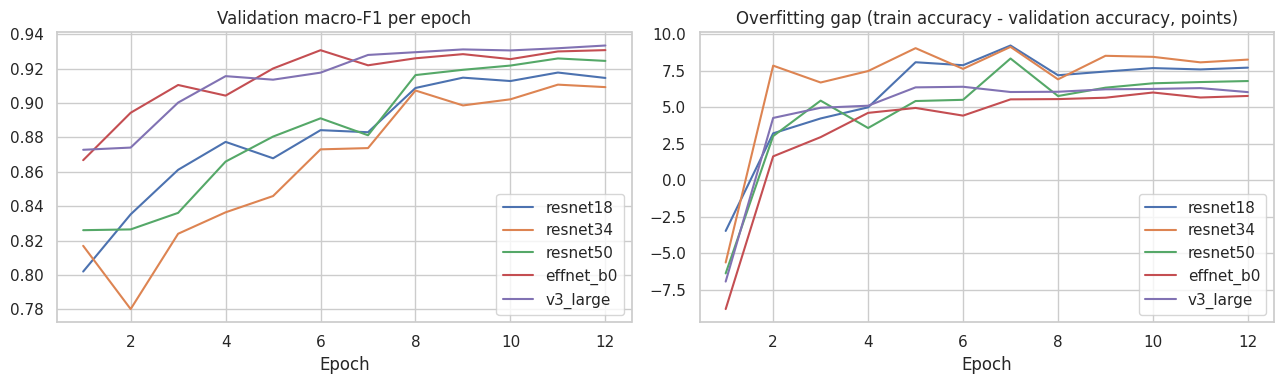

In [6]:
# WHAT: Plot each model's validation macro-F1 and its overfitting gap per epoch.
# WHY:  A gap that widens between training and validation accuracy is the standard sign of
#       overfitting. If validation is still rising at epoch 12, more epochs could help; if it
#       is flat, 12 was enough. A bigger model may overfit more than a small one.
# HOW:  Gap = training accuracy minus validation accuracy, in percentage points.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in RUN:
    h = runs[name]["history"]
    ep = range(1, len(h["val_f1"]) + 1)
    axes[0].plot(ep, h["val_f1"], label=name)
    axes[1].plot(ep, (np.array(h["train_acc"]) - np.array(h["val_acc"])) * 100, label=name)
axes[0].set_title("Validation macro-F1 per epoch")
axes[1].set_title("Overfitting gap (train accuracy - validation accuracy, points)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "benchmark_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** All five models reach 99% training accuracy by epoch 12, but validation stops at 92–93%, so every model overfits by a similar amount (about 6–7 points). The ResNets learn more slowly. ResNet-18 starts at 80.8% validation accuracy in epoch 1, against 87% for the lightweight models. All three ResNets reached their best epoch at 12, so they were still improving when training stopped. EfficientNet-B0 had already levelled off by epoch 6, and MobileNetV3-Large by epoch 7. The ResNets might gain a little with more epochs, but the recipe was fixed at 12 for fairness.

<a id="section-7"></a>
## Section 7: Test Results

**Goal:** Measure each model once on the held-out test set. The pooled score is flattered by catalogue-style images, so accuracy is also shown per data source: RealWaste is the closest to what the Pi camera will see.

In [7]:
# WHAT: Load each model's best checkpoint, predict the test set, and build one results table.
# WHY:  The test photos were never used for training or for choosing the best epoch, so
#       this is the honest dataset-level comparison. Plastic recall and the two plastic
#       mistakes (plastic called metal, plastic called glass) are included because they were
#       the weak point of the current model.
# HOW:  Predictions are collected with gradients off. Per-class recall (the share of each
#       class's test photos that were found) is kept for the heatmap below.
# ------------------------------------------------------------------------------------

def load_net(name):
    ck = torch.load(ckpt_path(name), map_location=device)
    net = build_model(name, pretrained=False).to(device)
    net.load_state_dict(ck["model_state"])
    return net.eval(), ck

ip, ig, im = (class_to_idx[c] for c in ["plastic", "glass", "metal"])
table, recall = [], {}
for name in RUN:
    net, ck = load_net(name)
    _, acc, p, y = run_epoch(net, test_loader)
    del net
    by_src = test_df.assign(pred=p).groupby("src").apply(
        lambda g: (g["pred"] == g["y"]).mean())
    cm = confusion_matrix(y, p, labels=list(range(len(class_names))))
    recall[name] = cm.diagonal() / cm.sum(axis=1)
    table.append({"model": name, "best epoch": ck["epoch"], "test acc": acc,
                  "test F1": f1_score(y, p, average="macro"),
                  "RealWaste": by_src["RealWaste"], "GD": by_src["GD"],
                  "Competition": by_src["Competition-only"],
                  "plastic recall": recall[name][ip],
                  "plastic->metal": int(cm[ip, im]), "plastic->glass": int(cm[ip, ig]),
                  "train min": runs[name]["minutes"]})
torch.cuda.empty_cache()

results = pd.DataFrame(table).set_index("model").join(spec)
display(results.round(3))

,best epoch,test acc,test F1,RealWaste,GD,Competition,plastic recall,plastic->metal,plastic->glass,train min,params (M),size (MB),CPU ms/photo
model,,,,,,,,,,,,,
resnet18,11,0.922,0.921,0.901,0.927,0.944,0.845,19,13,11.678,11.18,44.72,32.27
resnet34,11,0.921,0.922,0.900,0.928,0.942,0.845,20,15,11.675,21.29,85.16,55.03
resnet50,11,0.922,0.923,0.897,0.929,0.947,0.877,19,6,21.523,23.52,94.10,73.79
effnet_b0,12,0.943,0.943,0.938,0.940,0.961,0.880,17,12,11.056,4.02,16.07,30.00
v3_large,12,0.932,0.930,0.917,0.930,0.959,0.871,15,6,10.450,4.21,16.85,23.27


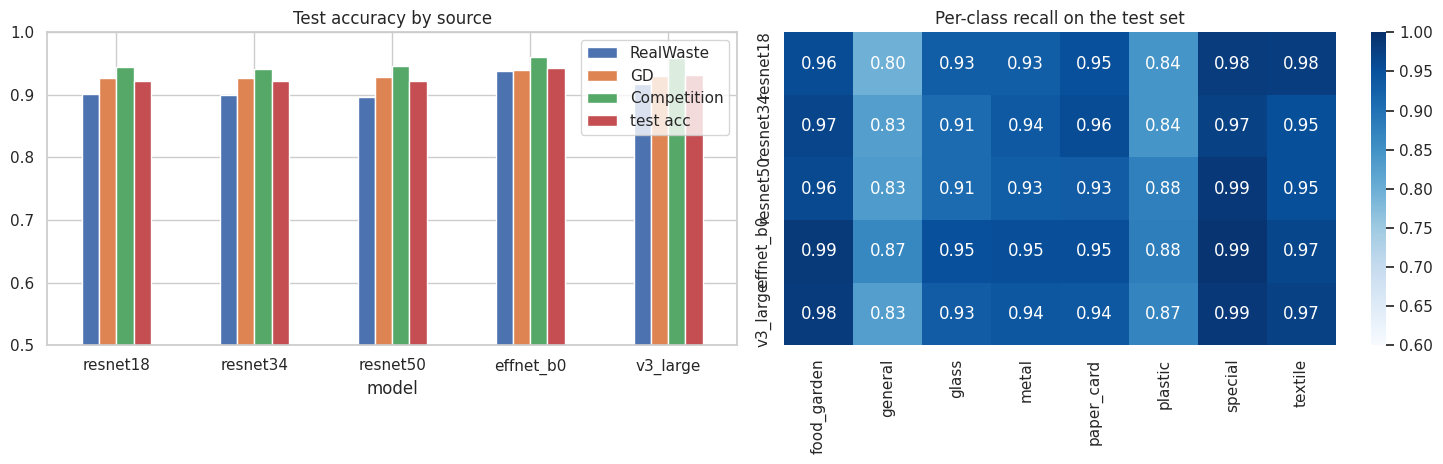

In [8]:
# WHAT: Draw accuracy by source as grouped bars, and per-class recall as a heatmap.
# WHY:  The bars show whether a model's gain is on the real floor photos or only on the
#       catalogue-style sources. The heatmap shows which classes each model is better or
#       worse at, especially plastic, glass, metal and general.
# HOW:  Each bar group is one source; each heatmap row is one model.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
results[["RealWaste", "GD", "Competition", "test acc"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("Test accuracy by source")
sns.heatmap(pd.DataFrame(recall, index=class_names).T, annot=True, fmt=".2f",
            cmap="Blues", vmin=0.6, vmax=1, ax=axes[1])
axes[1].set_title("Per-class recall on the test set")
plt.tight_layout()
plt.savefig(OUT / "benchmark_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Accuracy ranks EfficientNet-B0 (94.3%) first, then ResNet-50 (93.5%), MobileNetV3-Large (93.3%), ResNet-34 (92.8%) and ResNet-18 (92.1%). Most of these gaps are within about 1 point of run-to-run noise, so ResNet-50, ResNet-34 and MobileNetV3-Large are effectively tied. The clearest difference is on RealWaste, the photos closest to what the Pi camera will see: B0 scores 93.8% and the best ResNet 91.3%. That is about 2.5 points, roughly 17 photos out of 688. Depth did not help plastic, the hardest class. It is still 83.8–88.0% recall for every model, and plastic photos are still confused with metal (15–19 photos) and glass (5–13 photos).

<a id="section-8"></a>
## Section 8: Accuracy vs Speed

**Goal:** Put accuracy and speed on one chart. A model that is slightly more accurate but much slower may not be worth it on a Raspberry Pi.

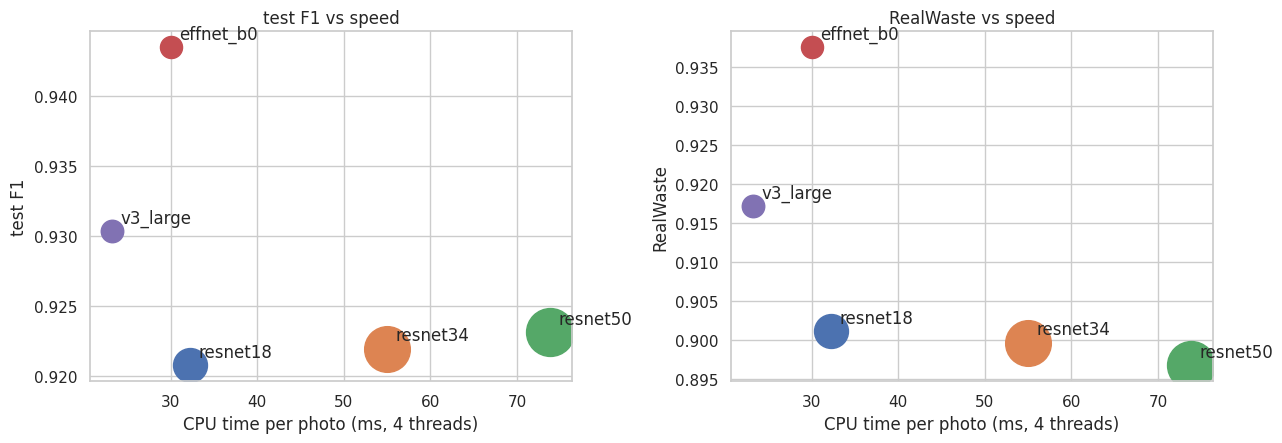

In [9]:
# WHAT: Plot CPU time per photo (x) against test macro-F1 and RealWaste accuracy (y).
# WHY:  The Pi has a time and memory budget, so the best model is the one that is accurate
#       enough and fast enough, not simply the most accurate.
# HOW:  One point per model; up and to the left is better. Larger markers are larger files.
# ------------------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, ["test F1", "RealWaste"]):
    for name, r in results.iterrows():
        ax.scatter(r["CPU ms/photo"], r[col], s=60 + r["size (MB)"] * 12)
        ax.annotate(name, (r["CPU ms/photo"], r[col]), xytext=(6, 6),
                    textcoords="offset points")
    ax.set_xlabel("CPU time per photo (ms, 4 threads)")
    ax.set_ylabel(col)
    ax.set_title(f"{col} vs speed")
plt.tight_layout(); plt.show()

**Finding:** ResNet-34 and ResNet-50 are slower and less accurate than both reference models. ResNet-18 is the only ResNet near the lightweight ones on speed, but it has the lowest accuracy of all five. No ResNet sits on the accuracy-speed frontier. MobileNetV3-Large is the fastest and EfficientNet-B0 is the most accurate.

<a id="section-9"></a>
## Section 9: Try Your Own Photos

**Goal:** Check the models on real photos from your own camera, which tells us more than the dataset score. Click **Choose file**, pick one or more photos from your PC, and each model's top-3 guesses are shown side by side. Below the 60% confidence threshold a model's answer is shown as "not sure", which is what the app would do.

In [10]:
# WHAT: A "Choose file" button. Each photo you pick is resized to 224x224 and added to
#       the page with the top-3 guesses of every trained model. Earlier results stay.
# WHY:  Dataset accuracy does not prove the model works on your camera. Adding photos one
#       by one lets you test many items in a row and compare the models on each.
# HOW:  After each pick the button is reset, so the next photo (even the same file) is
#       processed as new. "Clear results" wipes the page and the summary log.
# ------------------------------------------------------------------------------------

import io
import ipywidgets as widgets
from IPython.display import display

THRESHOLD = 0.60
nets = {name: load_net(name)[0] for name in RUN}
log = []                                    # one row per photo, for a summary table

def prepare(img):
    """Any PIL image -> normalised [3, 224, 224] tensor."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    return eval_transform(img)

def get_files(value):
    """Works with older (dict) and newer (tuple) ipywidgets."""
    if isinstance(value, dict):
        return [(n, bytes(f["content"])) for n, f in value.items()]
    return [(f["name"], bytes(f["content"])) for f in value]

def show_photo(name, data):
    raw = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(raw).convert("RGB")
    x = prepare(img).unsqueeze(0).to(device)
    row = {"photo": name[:30]}
    fig, axes = plt.subplots(1, 1 + len(nets), figsize=(3.4 * (1 + len(nets)), 3.4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(name[:28], fontsize=9)
    for ax, (model_name, net) in zip(axes[1:], nets.items()):
        with torch.no_grad():
            p = torch.softmax(net(x), 1)[0].cpu().numpy()
        top = np.argsort(-p)[:3][::-1]
        ax.barh([class_names[i] for i in top], p[top])
        ax.set_xlim(0, 1)
        answer = class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"
        ax.set_title(f"{model_name}: {answer} {p.max():.0%}", fontsize=9)
        row[model_name] = f"{answer} {p.max():.0%}"
    log.append(row)
    plt.tight_layout(); plt.show()

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Choose file")
clear_btn = widgets.Button(description="Clear results")
out = widgets.Output()

def on_upload(change):
    files = get_files(uploader.value)
    if not files:                           # the reset below triggers this once more
        return
    with out:
        for name, data in files:
            show_photo(name, data)
    uploader.value = {} if isinstance(uploader.value, dict) else ()   # ready for the next photo

def on_clear(_):
    out.clear_output()
    log.clear()

uploader.observe(on_upload, names="value")
clear_btn.on_click(on_clear)
display(widgets.HBox([uploader, clear_btn]), out)

Output()

<a id="section-10"></a>
## Section 10: Recommendation and Save

**Goal:** Choose the model with the best balance of accuracy and speed using a written rule, save the comparison, and save the chosen model as `verde_model.pth` for the live test and the Raspberry Pi export.

In [11]:
# WHAT: Apply a simple rule to choose a model, save the results, and write the chosen model
#       as verde_model.pth. Then reload that file and check it scores the same on the test set.
# WHY:  A written rule keeps the choice from being arbitrary: take the best test macro-F1,
#       but if a smaller, faster model is within MARGIN (1 point) of it, take the smaller
#       one, because a gap that small is within run-to-run noise. Change CHOSEN by hand if
#       the real-photo results in Section 9 point to another model.
# HOW:  The saved checkpoint keeps its "arch" key, so a later notebook rebuilds the right
#       network with build_model(arch) and does not have to assume one architecture.
# ------------------------------------------------------------------------------------

import shutil
MARGIN = 0.01
close = results[results["test F1"] >= results["test F1"].max() - MARGIN]
CHOSEN = close["CPU ms/photo"].idxmin()            # override here, e.g. CHOSEN = "v3_large"
print("Models within the margin:", list(close.index))
print("Chosen model:", CHOSEN)

results.round(4).to_csv(OUT / "benchmark_results.csv")
json.dump({"chosen": CHOSEN, "margin": MARGIN, "epochs": EPOCHS, "seed": SEED},
          open(OUT / "benchmark_summary.json", "w"), indent=2)
shutil.copy(ckpt_path(CHOSEN), OUT / "verde_model.pth")
json.dump(class_names, open(OUT / "class_names.json", "w"), indent=2)

# --- Reload the saved file on its own and re-measure it ---
ck = torch.load(OUT / "verde_model.pth", map_location=device)
net = build_model(ck["arch"], pretrained=False).to(device)
net.load_state_dict(ck["model_state"])
_, acc, _, _ = run_epoch(net.eval(), test_loader)
print(f"Reloaded verde_model.pth ({ck['arch']}): test accuracy {acc:.1%}")
print(f"Table value for {CHOSEN}: {results.loc[CHOSEN, 'test acc']:.1%}")

print("\nSaved files:")
saved = sorted(OUT.glob("verde_*.pth")) + [OUT / "class_names.json", OUT / "benchmark_results.csv"]
for f in saved:
    print(f"  {f.name:28s} {f.stat().st_size / 1024:8.1f} KB")

Models within the margin: ['effnet_b0']
Chosen model: effnet_b0


Reloaded verde_model.pth (effnet_b0): test accuracy 94.3%
Table value for effnet_b0: 94.3%

Saved files:
  verde_effnet_b0.pth           15989.1 KB
  verde_model.pth               15989.1 KB
  verde_resnet18.pth            43752.8 KB
  verde_resnet34.pth            83298.3 KB
  verde_resnet50.pth            92205.3 KB
  verde_v3_large.pth            16657.3 KB
  class_names.json                  0.1 KB
  benchmark_results.csv             0.6 KB


**Finding:** The rule chose EfficientNet-B0. The models within 0.01 of the best F1 were ResNet-50 and EfficientNet-B0, and B0 is the faster. MobileNetV3-Large misses the margin by 0.002 (0.931 against 0.943). The shortlist for the Pi stays the same: EfficientNet-B0 for accuracy and V3-Large for speed. The ResNets are dropped.

<a id="section-11"></a>
## Section 11: Summary and Limitations

**Summary:** EfficientNet-B0 won at 94.3% test accuracy and 93.8% on RealWaste. ResNet-50 came closest at 93.5% but is 5.9× bigger and 2.5× slower, so the lightweight models are the better fit for the Pi and the phone app. The real-photo test showed the same failures on electricals and wrappers for every model, so the next gain should come from Pi training photos plus the text-LLM clarification step.

**How to use the result**
1. Commit this notebook (Save & Run All) so the saved files exist as notebook output.
2. `verde_model.pth` stores the model name in `ckpt["arch"]`. A later notebook rebuilds the network with `build_model(arch)` (copy it from Section 4). The earlier live-test notebook assumes MobileNetV3-Small, so it needs that small change if another model wins. ResNets use only standard operations, so I expect them to export with ExecuTorch, but I have not verified it.
3. Measure the real inference time of the chosen model on the Raspberry Pi before exporting it with ExecuTorch.

**Limitations**
- Each model was trained once. One run has about 1 to 2 points of noise, so only clear gaps should drive a decision.
- Dataset test accuracy is flattered by catalogue-style photos. RealWaste and your own photos are the better guide, but a handful of photos is a rough check, not a score.
- The same learning rate and number of epochs were used for all models to keep the test fair. Each model might do slightly better with its own settings.
- ResNets need roughly 8 to 19 times the arithmetic of MobileNetV3-Large and their files are 45 to 95 MB, so even if they are accurate they may be too slow or too large for the Pi and a phone app.
- CPU times come from a Kaggle CPU, not a Raspberry Pi. Use them to compare the models with each other.
- A larger network cannot learn items it has never seen, such as watches, mice and other electricals. More training photos of those, taken with the Pi camera, will help more than a bigger model.

**Next steps:** capture Pi photos of electricals, batteries, textiles and glass and fine-tune the chosen model on them; add a "not sure" rule and a text language model to ask the user when the classifier is unsure; export the final model with ExecuTorch.